# AMP Designer: a step-by-step project walkthrough

## Goal

This guide walks through a simple question: **can we use information about a peptide to
predict whether it has recorded activity against *E. coli*?** You do not need previous
machine-learning experience to follow along.

To answer this question, we will first look at where the data came from and how we
cleaned it. From there, we will follow the model-building process and interpret the
results. As you work through the guide, you can run the cells to rebuild the tables
and figures. Once you understand those steps, the terminal commands near the end
show you how to rerun the actual modeling scripts.

**What we found:** our chosen model scored about **0.75 AUROC** on the final test set.
Although we will explain that score below, the main point is that the model found
useful predictive information. However, because the test set is small, this result
does not confirm that a new peptide will work in a lab.

**What Run All does:** it reads the small saved result files included with this notebook
and redraws the figures. It does not download DBAASP, train models, or repeat the final
model evaluation. The saved outputs are already visible if you only want to read.

## Setup: open the notebook and run the cells

Open the **whole `amp-designer` folder** in VS Code, then open
`notebooks/project_walkthrough.ipynb`. Keep its `data/walkthrough` folder in place;
that folder contains the saved summaries used by the cells.

Before running any cells, open a terminal in the project folder and create a separate
environment for the notebook:

```bash
python3 -m venv .venv-notebook
./.venv-notebook/bin/python -m pip install -r notebooks/requirements-notebook.txt
```

Once installation finishes, return to the notebook and click **Select Kernel**.
The kernel is simply the Python environment that runs your cells, so choose
`.venv-notebook/bin/python` and then click **Run All**. Alternatively, you can run
one cell at a time, starting at the top and working downward.

Because `.venv` holds the software used for the modeling experiment, we keep the
notebook environment separate. This lets you read and run the walkthrough without
changing the environment that produced the original model.

**Run the next cell:** it loads the saved summaries and sets up the plotting style.
It also checks file fingerprints—codes that help us notice if an input file has changed.
You should see “Verified five bundled input fingerprints,” followed by the Python and
Matplotlib versions used for this run. `source_manifest.json` lists where the summaries
came from; this check does not independently recreate the original experiment.

In [1]:
from pathlib import Path
import csv
import hashlib
import html
import json
import math
import platform
from importlib.metadata import version

import io
import matplotlib
matplotlib.use("Agg")  # Static, portable figure outputs; no GUI or external JS.
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, display

candidates = [Path.cwd() / "data/walkthrough",
              Path.cwd() / "notebooks/data/walkthrough"]
DATA_DIR = next((path for path in candidates if (path / "source_manifest.json").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Keep notebooks/data/walkthrough beside the notebook; run from the project root or notebooks folder.")

PRIMARY = "charge_corrected_amidation"
ORDER = ["dummy", "charge_uncorrected", "charge_corrected",
         PRIMARY, "composition", "physchem"]
NAMES = {"dummy": "Majority dummy", "charge_uncorrected": "Uncorrected charge",
         "charge_corrected": "Corrected charge", PRIMARY: "Charge + amidation (primary)",
         "composition": "Composition", "physchem": "Physicochemical"}
BLUE, ORANGE, GRAY = "#245B86", "#AD5A13", "#697580"
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 120,
                     "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 13,
                     "axes.titlepad": 14, "savefig.bbox": "tight"})

def table(headers, rows):
    def cell(value):
        return html.escape(str(value))
    head = "".join(f"<th style='text-align:left;padding:6px 12px'>{cell(x)}</th>" for x in headers)
    body = "".join("<tr>" + "".join(f"<td style='padding:5px 12px'>{cell(x)}</td>" for x in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

def show_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def load_csv(name):
    with (DATA_DIR / name).open(encoding="utf-8", newline="") as handle:
        return list(csv.DictReader(handle))

sources = json.loads((DATA_DIR / "source_manifest.json").read_text())
for name, details in sources["files"].items():
    assert hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() == details["sha256"], name
metrics = load_csv("metrics.csv")
intervals = load_csv("intervals.csv")
rankings = load_csv("precision_at_k.csv")
ladder = load_csv("feature_ladder.csv")
counts = json.loads((DATA_DIR / "reported_counts.json").read_text())
metric_index = {(row["panel"], row["model"]): row for row in metrics}
interval_index = {(row["panel"], row["model"], row["metric"]): row for row in intervals}
print("Verified five bundled input fingerprints.")
print(f"Notebook environment: Python {platform.python_version()}, Matplotlib {version('matplotlib')}")

Verified five bundled input fingerprints.
Notebook environment: Python 3.12.14, Matplotlib 3.10.8


## Steps

### 1. Decide what the model should predict

Our model predicts **active or inactive** from a peptide's amino-acid sequence and
whether its C-terminal end is amidated. Since amidation is a chemical change that
can affect activity, the sequence alone does not describe everything we want the
model to consider. We therefore include amidation as a separate input.

We define activity using **MIC**, or minimum inhibitory concentration: the lowest
reported concentration that stops visible bacterial growth. In this project, an MIC
at or below **32 µM** counts as active when the retained evidence supports that label.
This is our project cutoff, not a clinical treatment guideline. MIC measures growth
inhibition; it does not necessarily show that bacteria were killed.

With that definition in place, the problem becomes a classification task: the model
learns from examples with known labels and tries to predict a label for another input.
Its scope is limited to that activity label; it does not predict exact MIC, toxicity
or clinical effectiveness, and we have not built a peptide generator.

### 2. See what is in the dataset

Before we can assign those labels, we need to understand how DBAASP organizes its data.
Because one entry can contain several measurements, “2,217 entries” does not mean
“2,217 independent training examples.” We combine some entries and exclude others,
which is why the counts change as we move through the project.

A few terms will help you read the tables:

| Term in the outputs | What it means here |
|---|---|
| Record | One entry downloaded from DBAASP |
| Measurement | One reported activity result, with its recorded test conditions |
| Assay group | Measurements combined because their recorded conditions match |
| Modeled identity | One sequence together with its amidation state; our peptide example |
| Family | A group of similar sequences that we keep together when splitting data |

Matching recorded conditions do not guarantee that every unrecorded detail was the same.

**Run the next cell:** the left chart shows how many database entries pass the early
filters. The right chart shows the label status of the combined peptide examples.
Their units are different, so do not treat them as one continuous funnel. These counts
come from the saved project summary, `reported_counts.json`.

### How to read the data charts

The next figure has two separate horizontal bar charts. On each one, read the category
on the left and follow its bar to the number printed at the end. A longer bar means
more items in that category.

- **Left chart:** the horizontal axis counts database records. Follow the rows from
  top to bottom to see how many records remain after the early filters.
- **Right chart:** the horizontal axis counts combined peptide examples. Here the
  categories describe their final label status, rather than another sequence of filters.

For example, the left chart starts at 2,217 downloaded records, while the right chart
shows 271 active examples. These numbers count different things, so the second is not
an activity rate calculated out of the first.

Eligible broad labels: 489 identities across 486 sequences.


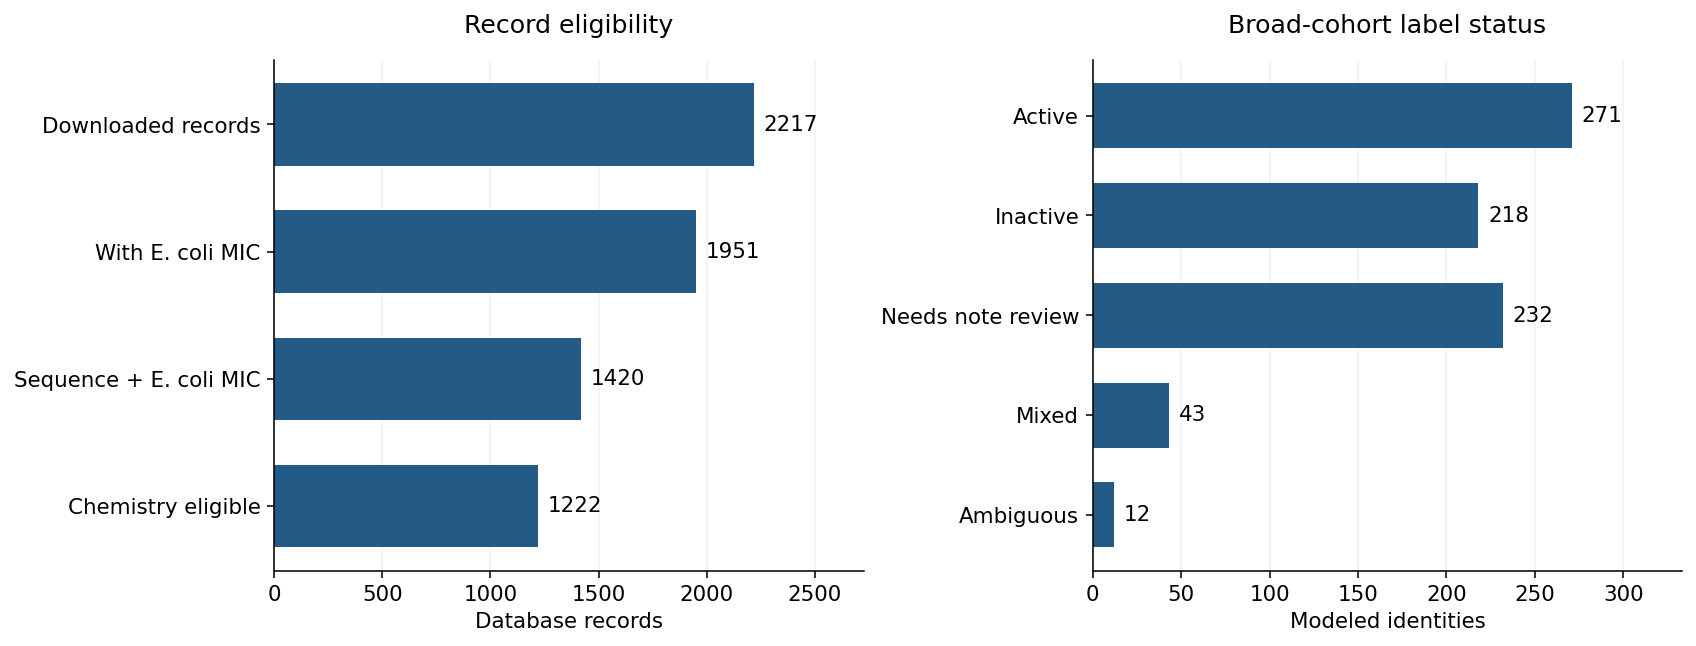

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for axis, values, title, unit in [
    (axes[0], counts["record_stages"], "Record eligibility", "Database records"),
    (axes[1], counts["broad_statuses"], "Broad-cohort label status", "Modeled identities")]:
    names, numbers = list(values), list(values.values())
    bars = axis.barh(names, numbers, color=BLUE, height=0.65)
    axis.invert_yaxis()
    axis.bar_label(bars, padding=5, fmt="%d")
    axis.set_xlim(0, max(numbers) * 1.23)
    axis.set_xlabel(unit)
    axis.set_title(title)
    axis.grid(axis="x", alpha=0.15)
    axis.set_axisbelow(True)
show_figure(fig)
print(f"Eligible broad labels: {counts['broad_statuses']['Active'] + counts['broad_statuses']['Inactive']} identities across {counts['ready_unique_sequences']} sequences.")

**What the bars show:** fewer records remain as we apply the eligibility checks,
and the right-hand chart shows a substantial group still needing note review.
The ready examples are the active and inactive groups together: 271 + 218 = 489.

We started with **2,217 entries** from a saved E. coli search, not the whole DBAASP database.
Of these, 1,951 contained an E. coli MIC measurement. However, having a measurement
was only the first requirement. After filtering, reviewing notes and combining
measurements, we had **489 peptide examples ready for classification**. Another 287
still had unresolved notes, unclear results or conflicting measurements, so we left
those out of the classifier.

### 3. Turn measurements into labels

To understand how we reached those 489 examples, let's look at the cleaning rules.
We began with a manageable scope: single-chain peptides of **10–50 amino acids**,
using the standard 20 amino-acid letters. Within that scope, we allowed C-terminal
amidation but excluded other recorded extra chemistry, such as additional bonds
or unusual residues.
A blank chemistry field means “nothing was recorded,” not proof that nothing was present.
Sequence letters alone cannot confirm all chemical details, including stereochemistry.

After checking the peptides themselves, we checked the bacterial strain, growth
medium, units and assay notes. The units are especially important because, for example,
we cannot directly compare a value in µg/mL with one in µM. Converting between them
requires the peptide's molecular weight, including the permitted terminal chemistry.
The exact conversion and filtering rules are in [the data policy](../docs/data_policy.md).

Once the retained measurements were in comparable units, we could ask:
**does the measurement clearly fall on one side of 32 µM?**
A range such as `8–16` is entirely below the cutoff, while `16–64` crosses it.
We keep those bounds rather than replacing a range with its midpoint. Expressions
such as `2.5 ± 0.5` are excluded under this version's conservative rules.

**Run the next cell:** it shows made-up examples to explain the rules. These are teaching
examples, not extra observations added to our dataset.

In [3]:
# Teaching examples only; the production parser and grouping rules live in build_labels.py.
table(["Synthetic reported MIC (µM)", "Interpretation at 32 µM"], [
    ("8", "Active: point value ≤32"),
    ("8–16", "Active: entire range ≤32"),
    ("≤16", "Active: upper bound ≤32"),
    (">64", "Inactive: lower bound exceeds 32"),
    ("16–64", "Ambiguous: range straddles the cutoff"),
])

<IPython.core.display.HTML object>

These rules become more important when a peptide has several measurements.
For example, results of `8`, `8–16` and `≤16` µM all support “active.” If the same
peptide also has a retained result of `>64`, however, the evidence disagrees.
Because we cannot give that example a consistent label, we flag it and leave it
out of the first classifier rather than choosing a label by majority vote.

Applying these rules gives us a main dataset that includes accepted measurements
from laboratory/reference strains,
clinical isolates and cases where strain origin is unspecified. Clinical-isolate
measurements are not automatically invalid, and an empty note does not prove that
an assay used a reference strain. We call this combined dataset the **broad cohort**.

### 4. Split the data without giving the model an easy test

Now that we have labeled examples, we need to decide which ones to use for training
and which ones to save for testing. Imagine training on a peptide and then testing
on a nearly identical version: the model might score well without learning much
that transfers to different peptides.
To reduce this problem, we group similar sequences into families and keep each family
together when assigning training and test examples. Amidation variants stay together too.

The saved split uses an **80% global edit-similarity rule**. In plain terms, it considers
how many amino-acid changes, insertions or deletions separate two complete sequences,
relative to the longer sequence. Linked sequences form groups, including links through
other sequences. This is a practical rule; it does not prove biological relatedness
or catch every shared motif.

We grouped all 772 sequences in the broad audit without using their activity labels.
We also set aside the clinical-only families before assigning the other groups.

**Run the next cell:** it shows the saved training, test and clinical partitions.
These assignments stay fixed when we reproduce the experiment.

In [4]:
table(["Partition", "Identities", "Unique sequences", "Families", "Active", "Inactive"],
      [[r[k] for k in ("partition", "identities", "sequences", "families", "active", "inactive")]
       for r in counts["partitions"]])
assert sum(r["identities"] for r in counts["partitions"]) == 489
assert all(r["active"] + r["inactive"] == r["identities"] for r in counts["partitions"])

<IPython.core.display.HTML object>

This splitting process leaves **394 peptide examples for training** and **71 for
the primary test**, which we kept out of model selection. Alongside those two sets,
we kept a small clinical set for an exploratory check. We also set aside related
examples in the clinical family buffer so they would not enter training.
Its two families are already part of the clinical reservation, so those family counts
should not be added as independent groups.

Our grouping rule has limits: a short fragment of a longer peptide can look quite
different under a whole-sequence comparison. Before final evaluation, we therefore
also checked local sequence matches and defined stricter test subsets. We return
to their results in Step 7; [the methods document](../docs/final_results.md) has the
alignment settings if you want to reproduce that diagnostic in detail.

### 5. Compare models using training data

With the split fixed, we could start comparing models using the training data.
We began with a simple reference: always guessing the most common class. We then
compared that guess with several logistic regression models, which combine input
features into a score used to predict active or inactive.

To compare these models without using the final test set, we used **five-fold
cross-validation**. We split the training families into five parts, fitted each
model on four parts, and checked its predictions on the remaining part. By repeating
this process, every part was checked once. Because all models used the same saved
folds, their results were easier to compare fairly.
Any feature scaling was learned only from that round's fitting data.

Within each of those fitting rounds, the models received different sets of features.
The simplest useful features describe charge, which we estimated as
`number of K and R residues − number of D and E residues + 1 if amidated`.
It is an estimate based on counts, not a full calculation of charge at a particular pH.
Other models use amino-acid composition or a larger set of physical/chemical summaries.

Along with the feature sets, we tried several values of **C**, a logistic-regression
setting that controls
regularization. Smaller C penalizes large model weights more strongly. We chose C
using the training cross-validation results, never the final test results.

**Run the next cell:** it plots the saved development results from `feature_ladder.csv`.
“OOF” means *out of fold*: each plotted prediction came from a fitting round that did
not include that example. The chart combines those predictions into one AUROC score.
The intervals were estimated by repeatedly resampling whole sequence families from
the saved predictions. The reading guide below explains how to interpret those scores
and intervals together.

### How to read the development comparison

Each row in the next chart is a model, and the horizontal axis is AUROC. To read a row,
start at its dot and trace down to the score on the axis; the printed number on the
right gives the same estimate. Farther right means better ranking in these saved
cross-validation predictions.

The **orange diamond** marks our chosen charge-plus-amidation model, while blue circles
mark the other models. The dashed vertical line at **0.5** is the chance-ranking
reference. The horizontal line through each point is its 95% uncertainty interval:
a longer line means a less precise estimate under the resampling procedure.

Notice both the score and its interval. A point farther right is a higher estimate,
but that alone does not establish that its model is better. Also, overlap between
separate intervals is not a formal test of the difference; we use the paired
comparison described after the figure.

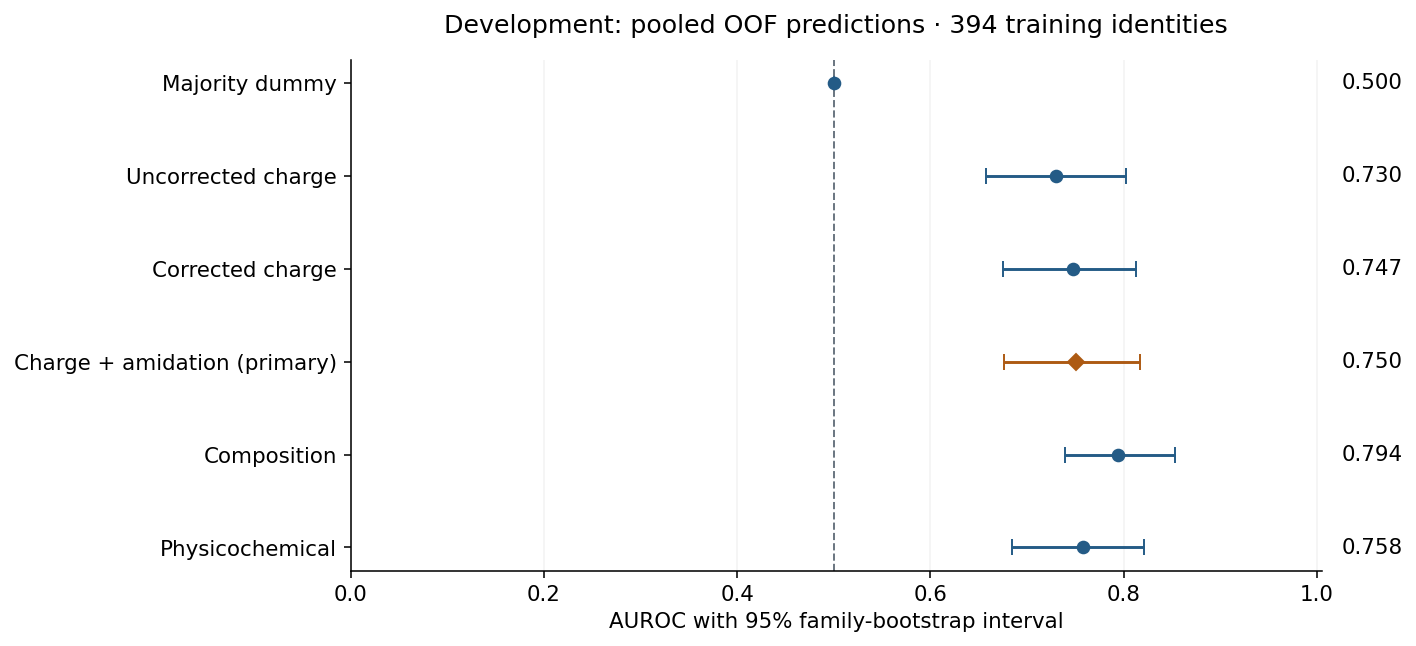

In [5]:
def forest(axis, entries, title):
    for index, (label, estimate, low, high, primary) in enumerate(entries):
        color = ORANGE if primary else BLUE
        axis.errorbar(estimate, index, xerr=[[estimate-low], [high-estimate]],
                      fmt="D" if primary else "o", color=color, capsize=4, markersize=6)
        axis.text(1.02, index, f"{estimate:.3f}", va="center", transform=axis.get_yaxis_transform())
    axis.set_yticks(range(len(entries)), [entry[0] for entry in entries])
    axis.invert_yaxis()
    axis.axvline(0.5, color=GRAY, linestyle="--", linewidth=1, label="Chance AUROC")
    axis.set_xlim(0, 1.005)
    axis.set_xlabel("AUROC with 95% family-bootstrap interval")
    axis.set_title(title)
    axis.grid(axis="x", alpha=0.15)

ladder_by_model = {r["model"]: r for r in ladder}
entries = []
for model in ORDER:
    row = ladder_by_model[model]
    entries.append((NAMES[model], float(row["pooled_oof_roc_auc"]),
                    float(row["pooled_oof_roc_auc_low"]), float(row["pooled_oof_roc_auc_high"]), model == PRIMARY))
fig, axis = plt.subplots(figsize=(10, 4.5), layout="constrained")
forest(axis, entries, "Development: pooled OOF predictions · 394 training identities")
show_figure(fig)

**What the development chart shows:** every logistic model has a higher AUROC
estimate than the dummy. Composition has the highest point estimate, while the
chosen primary model has a point estimate close to those of several simpler alternatives.
To assess the composition-versus-primary difference, we also use the paired comparison below.

The charge-plus-amidation model had a combined development AUROC of about **0.750**.
Composition scored higher at **0.794**, but the uncertainty in their paired difference
included zero. That comparison did not give us clear evidence that composition was
better; it also did not prove the models were equivalent.

Given that comparison, we chose the simpler charge-plus-amidation model as our
**primary model** before opening
the final test outcomes. It uses two features: the corrected charge estimate and a
separate amidation indicator. Its selected C is **0.1**.

The development intervals use 2,000 family resamples with saved predictions held fixed.
They do not capture every source of uncertainty, such as choosing settings using the
same development data or training a model again on another dataset.

### 6. Read the final test results

Once we had recorded those choices, we were ready to evaluate the fixed list of
models on the test set. We kept the chosen primary model even if another model
happened to score higher there, because switching at that point would turn the
test set into another model-selection set.

Two scores are useful here:

- **AUROC:** how well the model ranks active above inactive examples. A value of 0.751
  means roughly a 75% chance for a randomly chosen active/inactive pair, with half
  credit for tied scores.
- **Balanced accuracy:** the average of the fraction of active examples found and the
  fraction of inactive examples correctly rejected. It gives both classes equal importance.

The model predicts active when its probability score is above **0.5**; an exact tie is
inactive. This is a different cutoff from **32 µM**, which defines the training labels.

**Run the next cell:** it reads the saved test scores and intervals from `metrics.csv`
and `intervals.csv`. It displays the results without evaluating a model again.

### How to read the final test comparison

This chart uses the same model rows, symbols and AUROC scale as the development chart,
but the predictions now come from the **71 held-out test examples**. The orange diamond
again identifies the model chosen before testing. Its position tells you the estimated
ranking performance, and its horizontal line shows the uncertainty around that estimate.

For example, the primary model's point is near 0.75, with its line stretching from
about 0.59 to 0.89. Read those together: the estimate is encouraging, but it is not
precise. Although another model's point may sit farther right, we report that result
without switching the primary model after seeing test performance.

Below the chart, the table lists other measures for the primary model. AUROC describes
ranking, whereas precision, sensitivity and specificity describe its classifications
at the fixed 0.5 prediction cutoff.

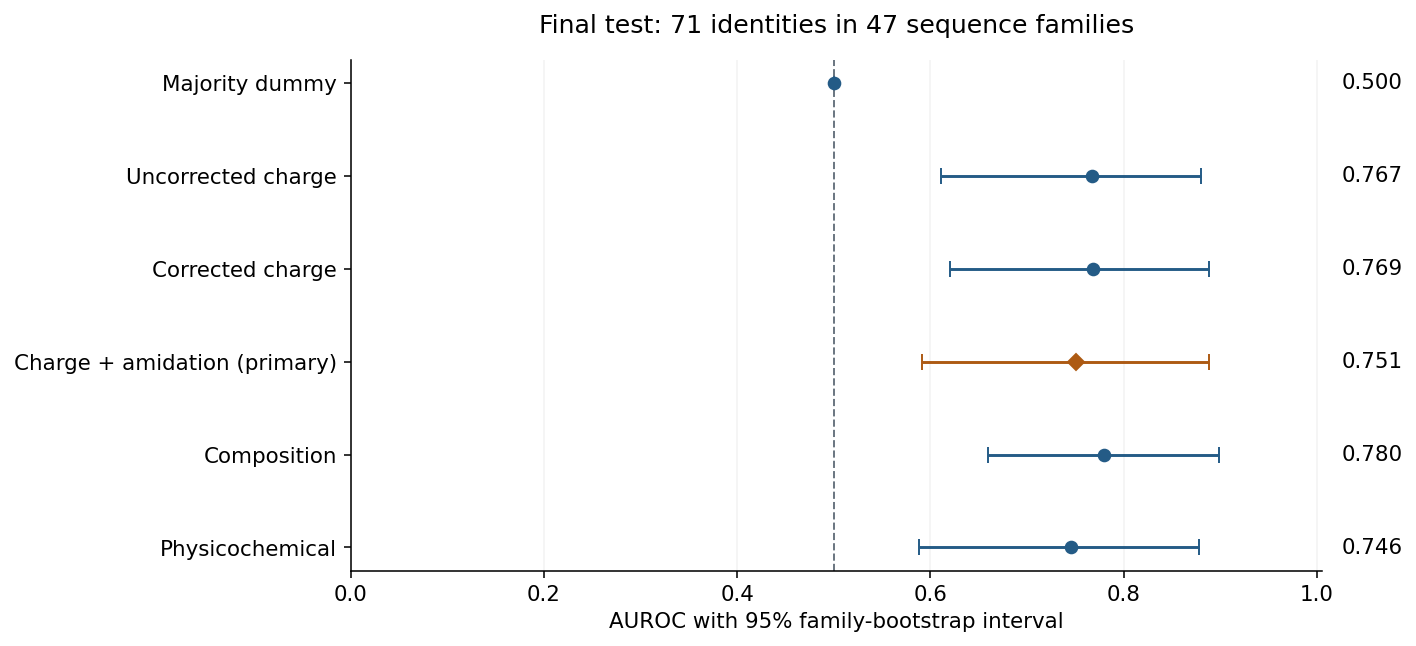

<IPython.core.display.HTML object>

In [6]:
entries = []
for model in ORDER:
    row = interval_index[("overall", model, "roc_auc")]
    entries.append((NAMES[model], float(row["estimate"]), float(row["low"]), float(row["high"]), model == PRIMARY))
fig, axis = plt.subplots(figsize=(10, 4.5), layout="constrained")
forest(axis, entries, "Final test: 71 identities in 47 sequence families")
show_figure(fig)
primary = metric_index[("overall", PRIMARY)]
selected_metrics = ["balanced_accuracy", "roc_auc", "precision", "sensitivity", "specificity", "mcc"]
table(["Primary metric", "Estimate", "95% interval"],
      [(name.replace("_", " "), f"{float(primary[name]):.3f}",
        f"{float(interval_index[('overall', PRIMARY, name)]['low']):.3f}–{float(interval_index[('overall', PRIMARY, name)]['high']):.3f}")
       for name in selected_metrics])

**What the test chart shows:** the primary model ranks above the chance reference,
but its long interval shows why the score should not be read as an exact capability.
The other model estimates are fairly close, and this figure alone does not establish
a reliable ordering among them.

Our primary model's test AUROC was **0.751**, with a 95% interval of **0.592–0.888**.
Its balanced accuracy was **0.717**, with interval **0.593–0.874**. Although these
scores suggest useful predictive information, the intervals show that the estimates
are uncertain. With only 71 test examples, we can make a useful final check, but
cannot reliably settle small differences between models.

The test intervals used 5,000 family resamples of the saved predictions. They describe
uncertainty under that procedure, not everything that could change if we collected
new data, reviewed different notes or trained again.

To see what those scores mean in terms of individual predictions, **run the next
cell**. It shows the primary model's confusion matrix—a count of correct
and incorrect predictions. Rows are recorded labels; columns are predicted labels.

### How to read the confusion matrix

The next figure turns the model's classifications into four counts. **Rows show the
recorded activity label**, and **columns show the model's prediction**.

| Position in the matrix | What it counts |
|---|---|
| Top left | Recorded inactive and predicted inactive: correct rejections |
| Top right | Recorded inactive but predicted active: false positives |
| Bottom left | Recorded active but predicted inactive: false negatives |
| Bottom right | Recorded active and predicted active: correct detections |

The darker squares contain more examples; the numbers are counts, not percentages.
To see how often an active example was found, read across the bottom row. To see how
trustworthy an active prediction was in this test pool, read down the right column.

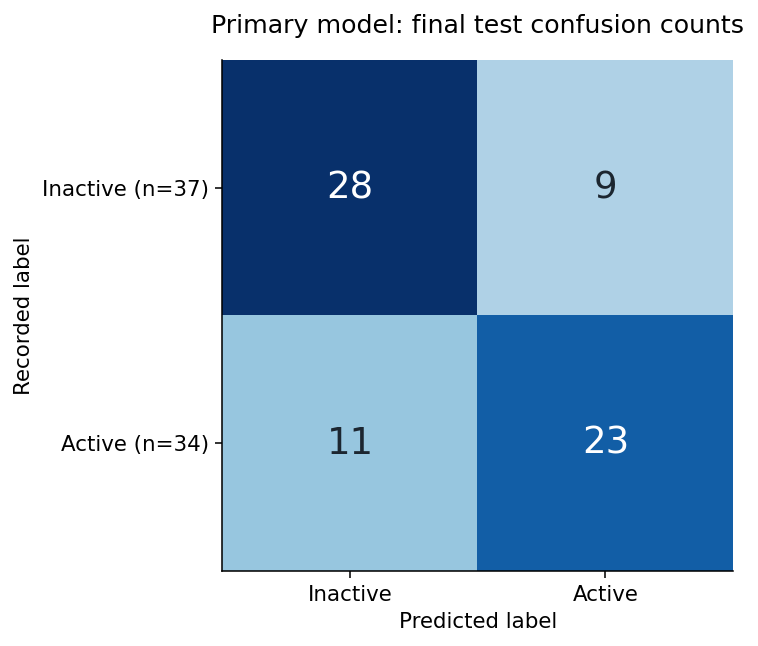

In [7]:
confusion = [[int(float(primary["tn"])), int(float(primary["fp"]))],
             [int(float(primary["fn"])), int(float(primary["tp"]))]]
fig, axis = plt.subplots(figsize=(6.5, 4.5), layout="constrained")
axis.imshow(confusion, cmap="Blues", vmin=0, vmax=max(map(max, confusion)))
for i in range(2):
    for j in range(2):
        value = confusion[i][j]
        axis.text(j, i, str(value), ha="center", va="center", fontsize=19,
                  color="white" if value > 18 else "#1C2630")
axis.set_xticks([0, 1], ["Inactive", "Active"])
axis.set_yticks([0, 1], ["Inactive (n=37)", "Active (n=34)"])
axis.set_xlabel("Predicted label")
axis.set_ylabel("Recorded label")
axis.set_title("Primary model: final test confusion counts")
show_figure(fig)

Reading across the rows, the model correctly found **23 of 34 active** examples
and missed 11. Among the inactive examples, it correctly rejected **28 of 37**
and mistakenly called nine active. We can also read down the predicted-active
column: 23 of those 32 examples were recorded active, giving **71.9% precision**.
These are results on database examples, not newly completed lab experiments.

### 7. Check performance on less-similar sequences

The full test gives us an overall result, but we also wanted to know whether the
model could work on less-similar sequences. Before evaluating the test set, we
therefore marked subsets with no training neighbor above the
chosen similarity limits. “Global strict” uses the whole-sequence comparison. “Combined
strict” also applies the local-match check. These are extra checks alongside the full
test result, not alternative test sets from which we choose the nicest score.

**Run the next cell:** it compares the primary model's AUROC on those saved subsets
and prints a short summary of the small clinical set.

### How to read the subset comparison

Every point in the next chart comes from the **same primary model**. What changes
between rows is the group of test examples being evaluated. The top orange diamond
is the full test set; the blue circles show the stricter similarity subsets.
As before, the horizontal axis is AUROC, and the lines show 95% uncertainty intervals.

The `n` beside each row is the number of peptide examples in that group. Read it
alongside the score: the combined subset has only 32 examples, compared with 71 overall.
A point farther right in a smaller subset is not automatically evidence that the
model works better on unfamiliar peptides. The membership changes, and the estimate
is less precise. The dashed 0.5 line is again the chance-ranking reference.

Clinical exploratory: n=17, active=14, inactive=3.
Balanced accuracy 0.595; specificity 0.333.
Clinical AUROC interval suppressed: AUROC interval support below frozen minimum (10 groups, 5 examples/class)


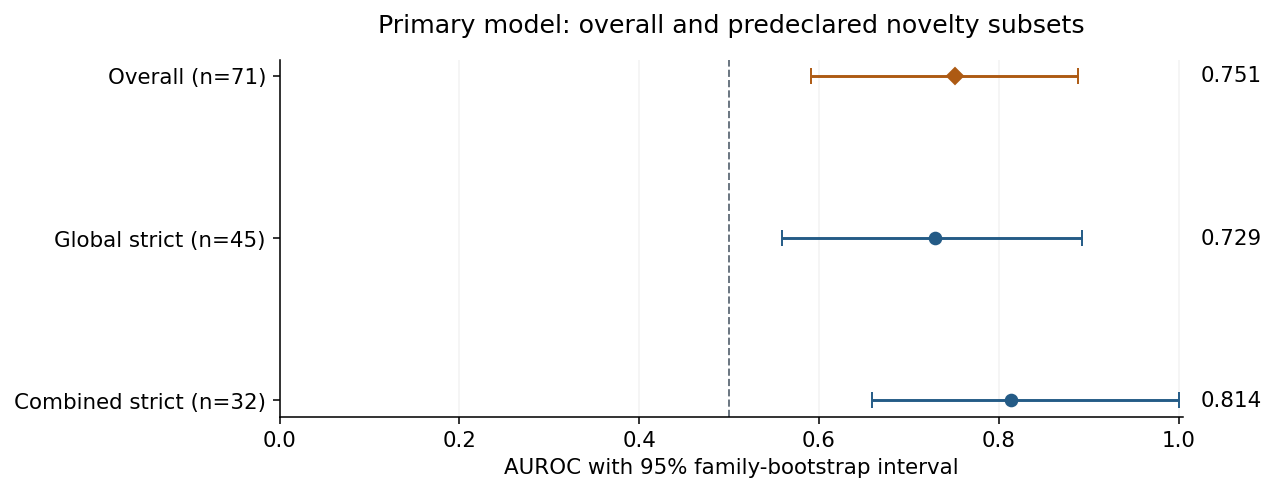

In [8]:
panels = [("overall", "Overall (n=71)"), ("global60_strict", "Global strict (n=45)"),
          ("combined60_strict", "Combined strict (n=32)")]
entries = []
for panel, label in panels:
    row = interval_index[(panel, PRIMARY, "roc_auc")]
    entries.append((label, float(row["estimate"]), float(row["low"]), float(row["high"]), panel == "overall"))
fig, axis = plt.subplots(figsize=(9, 3.4), layout="constrained")
forest(axis, entries, "Primary model: overall and predeclared novelty subsets")
show_figure(fig)
clinical = metric_index[("clinical_exploratory", PRIMARY)]
clinical_auc_interval = interval_index[("clinical_exploratory", PRIMARY, "roc_auc")]
print(f"Clinical exploratory: n={clinical['n']}, active={clinical['active']}, inactive={clinical['inactive']}.")
print(f"Balanced accuracy {float(clinical['balanced_accuracy']):.3f}; specificity {float(clinical['specificity']):.3f}.")
print("Clinical AUROC interval suppressed:", clinical_auc_interval["interval_suppressed_reason"])

**What the subset chart shows:** the combined-subset point is farther right than
the overall point, but its interval is wide and its sample is smaller. We therefore
report it as an additional check, without claiming improved generalization.

The combined strict subset has only **32 examples**. Its AUROC is **0.814**, but the
interval is wide (**0.659–1.000**). The higher score does not show that prediction gets
better on new peptides: this is a smaller, different group. The local and combined
subsets contain the same examples here, so they are not two independent confirmations.

We need even more caution with the clinical set because it contains 14 active
examples and only
**three inactive** ones; the model correctly rejects just one of those three.
Balanced accuracy is **0.595**. We leave the clinical AUROC interval blank because
there are too few inactive examples under our predefined reporting rule—not because
the interval is zero. The broad training data can include other clinical-origin assays,
so this is not a clean reference-strain-to-clinical transfer experiment.

### 8. Ask whether ranking could help choose a short list

So far, we have looked at predictions across whole groups of examples. In practice,
however, a researcher may only be able to test a short list of candidates. To explore
that use case, we report **precision@k**: the fraction of the top k scored examples
that are recorded active. We fixed k at 5, 10 and 20 before the final evaluation.

**Run the next cell:** it reads `precision_at_k.csv` and shows two ways of making the
list: use all peptide examples, or keep one top-scoring example per sequence family.
When scores tie, the calculation averages across tied choices, so some values are
fractional. The intervals again come from resampling families of saved predictions.

### How to read the short-list chart

The horizontal axis shows the list size: the **top 5, top 10 or top 20** scored examples.
The vertical axis shows the fraction of that list recorded as active. For instance,
0.8 means 80% of the list, so a top-10 value of 0.8 corresponds to eight active examples
when there is no boundary-tie averaging to account for.

Blue circles use all identities, while orange diamonds keep one representative per
sequence family. Their slight left/right offset just keeps the marks readable; both
marks at “Top 10” use a list size of ten. Each vertical line gives a 95% uncertainty
interval rather than the spread of individual peptide scores.

The dashed horizontal line marks the **47.9% active share in the all-identity test pool**.
It provides context for that pool, not an exact random baseline for the different
one-per-family pool. Look at the intervals as well as the points before drawing a
conclusion about how useful the ranking might be.

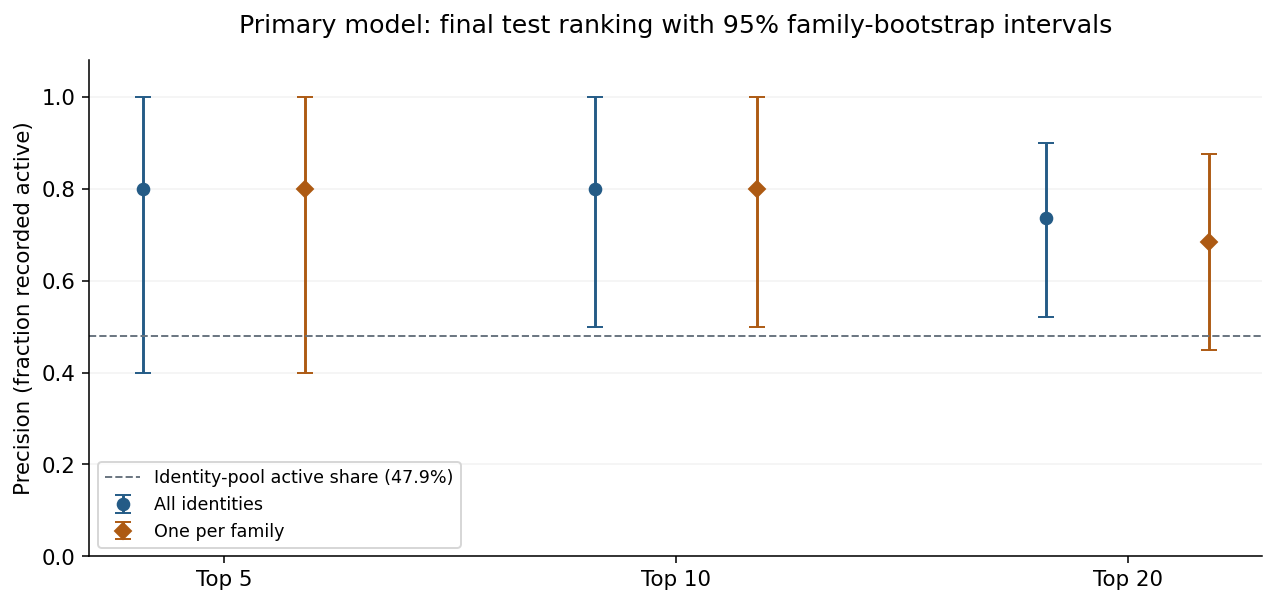

In [9]:
fig, axis = plt.subplots(figsize=(9, 4.2), layout="constrained")
modes = [("all_identities", "All identities", BLUE, "o", -0.18),
         ("one_representative_per_80pct_family", "One per family", ORANGE, "D", 0.18)]
for mode, label, color, marker, offset in modes:
    selected = sorted([r for r in rankings if r["panel"] == "overall" and r["model"] == PRIMARY
                       and r["ranking_mode"] == mode], key=lambda r: int(r["k"]))
    x = [i + offset for i in range(len(selected))]
    y = [float(r["expected_precision_at_k"]) for r in selected]
    axis.errorbar(x, y, yerr=[[v-float(r["low"]) for v, r in zip(y, selected)],
                            [float(r["high"])-v for v, r in zip(y, selected)]],
                  fmt=marker, color=color, capsize=4, label=label)
prevalence = int(primary["active"]) / int(primary["n"])
axis.axhline(prevalence, color=GRAY, linestyle="--", linewidth=1,
             label=f"Identity-pool active share ({prevalence:.1%})")
axis.set_xticks([0, 1, 2], ["Top 5", "Top 10", "Top 20"])
axis.set_ylim(0, 1.08)
axis.set_ylabel("Precision (fraction recorded active)")
axis.set_title("Primary model: final test ranking with 95% family-bootstrap intervals")
axis.legend(loc="lower left", fontsize=9)
axis.grid(axis="y", alpha=0.15)
show_figure(fig)

**What the short-list chart shows:** both ranking modes reach a top-10 estimate
of 0.80, above the all-identity pool's active share. However, their intervals run
from 0.50 to 1.00, so this small test does not support a precise hit-rate promise.

Top-10 precision was **0.80**, with a 95% interval of **0.50–1.00**, in both ranking
modes. For context, 47.9% of all identities in the test pool were recorded active.
That percentage describes the whole identity pool, not an exact random baseline
for the different one-per-family pool.

Although this is encouraging for a simple baseline, it does not promise an 80%
laboratory success rate for new peptides. Since the model uses only two features,
different sequences can receive identical scores. In addition, we have not shown
that its probabilities are calibrated:
a score of 0.8 should not be read as a proven 80% chance of experimental success.

### 9. See what changes when we change the activity definition

All of the results above use the same activity definition, which raises another
question: why choose 32 µM rather than 16 or 64? Because that cutoff is a project
decision, we checked how changing it would affect both labels and which examples
were usable. We restricted this check to training-assigned families and kept the
primary cutoff at 32 µM throughout.

**Run the next cell:** it displays the saved cutoff comparison in `reported_counts.json`.
It does not train or evaluate models at new cutoffs. Rebuilding at 32 µM reproduced
all 394 original training labels exactly.

In [10]:
sensitivity = counts["sensitivity_original_training"]
table(["MIC cutoff (µM)", "Eligible", "Active", "Inactive", "Excluded", "Definite label flips from 32"],
      [[r[k] for k in ("threshold_uM", "eligible", "active", "inactive", "excluded", "definite_label_changes")]
       for r in sensitivity])
assert next(r for r in sensitivity if r["threshold_uM"] == 32)["active"] == 217
assert all(r["active"] + r["inactive"] == r["eligible"] and r["eligible"] + r["excluded"] == 394
           for r in sensitivity)

<IPython.core.display.HTML object>

The table shows that, at 16 µM, 17 original training examples no longer had clear,
consistent labels, while 30 still-eligible examples changed labels. At 64 µM,
14 were excluded and 25 changed labels. In other words, changing the cutoff
affects both the labels and the membership of the usable dataset.

The wider training-family audit also found 15 previously unready examples that became
eligible at 16 µM and 14 at 64 µM. We did not add these to the fixed training set or
choose a new cutoff based on model performance. The primary cutoff remains **32 µM**.

### 10. Find the scripts that do the actual work

Now that we have worked through the results, we can connect each stage to the
files you would use for a rerun. While this notebook explains the process and
redraws saved results, the Python scripts below perform the underlying project steps. The historical name `download_pilot.py` is a
little misleading: it can download the full collection when given the full manifest.
A manifest is simply the saved list of database IDs selected for a run.

**Run the next cell:** it displays the file map. You do not need to run every script
to refresh this notebook or to use the saved predictor.

In [11]:
table(["Files", "Role"], [
    ("data_utils.py", "Shared paths, validated JSON IO, API/filter helpers"),
    ("prepare_pilot.py / prepare_full.py", "Save the selected ID manifest"),
    ("download_pilot.py / audit_pilot.py", "Download/resume or audit a manifest-defined cohort"),
    ("build_labels.py / build_provenance.py", "Apply chemistry, assay, note and identity-label rules"),
    ("prepare_splits.py", "Protect sequence families across train/test/clinical reservation"),
    ("modeling/train_baseline.py / compare_features.py", "Fit/select on training data; share CV folds"),
    ("modeling/prepare_evaluation.py", "Record fixed models, diagnostic subsets and protocol before testing"),
    ("modeling/check_label_sensitivity.py", "Check label/eligibility changes in training-assigned families"),
    ("modeling/evaluate_holdout.py", "Perform the now-completed fixed evaluation; preserve outputs"),
    ("modeling/predict.py", "Load the trusted frozen primary model and score valid inputs"),
    ("This notebook", "Explain saved evidence; no new fitting or held-out evaluation"),
])

<IPython.core.display.HTML object>

### Try the saved predictor

Run this in your **terminal**, from the project folder:

```bash
python3 modeling/predict_portable.py --sequence AAAAAAAAAA --unmodified
```

`AAAAAAAAAA` is a made-up syntax example, not a recommended candidate. You should get
an inactive prediction and a model score of about **0.16963**. Use `--amidated` instead
when that terminal change applies. The command uses the saved model parameters and
standard Python; it does not train a model. The notebook does not run it automatically.

### Rerun the training experiment

Use Python **3.13.4** to match the original experiment. If you already have the project's
modeling `.venv`, use it. For a fresh clone without that environment, run these terminal
commands from the project folder:

```bash
python3 --version
python3 -m venv .venv
./.venv/bin/python -m pip install -r requirements.txt
```

Check the version first; do not recreate or upgrade an existing modeling environment
just to run the notebook. Then verify the saved inputs and reproduce the training work:

```bash
./.venv/bin/python tools/verify_release.py
./.venv/bin/python tools/reproduce_modeling.py
```

The first command checks that your inputs match the recorded file fingerprints.
Once that check passes, the second command trains reproduction copies using the
saved choices, compares their training results with the original reports, and
repeats the training-only cutoff check. As it runs, look for
**PASS** messages for the baseline, feature comparison and label-sensitivity exports.
New outputs go under `results/reproduced/`; original reports are kept intact.
The command does **not** repeat final test evaluation or use it to tune a model.

Because these commands start from the prepared tables included in the repo, you
do not need to download DBAASP again to reproduce the modeling results. If you
want to rebuild from live DBAASP instead, that is a separate, best-effort process
because database entries can change.
See [the reproduction guide](../docs/reproduce.md) for that workflow and troubleshooting.

## Checks: did this notebook run successfully?

**Run the next cell:** it checks that the saved counts and metrics agree with one another.
The final message should begin **“Checks passed.”** You should also have seen six figures
and no red error messages while running the notebook from top to bottom.
These are consistency checks on saved summaries, not a new validation of every raw record.

In [12]:
assert len(metrics) == 30 and len(metric_index) == 30
assert len(intervals) == 240 and len(interval_index) == 240
assert len(rankings) == 180
for row in metrics:
    tn, fp, fn, tp = [float(row[key]) for key in ("tn", "fp", "fn", "tp")]
    assert tn + fp + fn + tp == int(row["n"])
    assert tp + fn == int(row["active"]) and tn + fp == int(row["inactive"])
    assert math.isclose(float(row["balanced_accuracy"]), (tp/(tp+fn) + tn/(tn+fp))/2)
    assert math.isclose(float(row["accuracy"]), (tp+tn)/int(row["n"]))
for row in intervals:
    assert math.isclose(float(row["estimate"]), float(metric_index[(row["panel"],row["model"])][row["metric"]]))
    if row["low"]:
        assert float(row["low"]) <= float(row["high"])
for row in rankings:
    if row["expected_precision_at_k"]:
        assert 0 <= float(row["expected_precision_at_k"]) <= 1
    if int(row["k"]) > int(row["candidate_pool"]):
        assert row["expected_precision_at_k"] == ""
assert (int(float(primary["tp"])), int(float(primary["tn"]))) == (23, 28)
assert math.isclose(float(primary["roc_auc"]), 0.7507949125596184)
print("Checks passed: source fingerprints, counts, confusion arithmetic, interval estimates and ranking limits.")

Checks passed: source fingerprints, counts, confusion arithmetic, interval estimates and ranking limits.


## Next Steps

You have now followed the project from a biological question to cleaned labels, grouped
model development, a final test and a usable prediction command.

The main finding is modest but useful: **charge-related features contain predictive
information in this filtered dataset**. The chosen model's test AUROC is about 0.75,
with a wide uncertainty interval. We did not replace it using test-set scores.

Keep these limits in mind if you extend the project:

- The model cannot confirm activity, toxicity or clinical effectiveness for a new peptide.
- We left out unclear and conflicting examples, which may make the task easier.
- The unresolved review queue leans active: 180 of its 232 examples have provisional
  active-only evidence, 45 inactive-only evidence and seven no definite group.
  Those provisional cases are not accepted labels.
- Similar sequences, shared studies and missing assay details may still affect the results.
- The final test outcomes are now known. A future model needs a new independent
  evaluation resource; repeatedly tuning against this test would weaken its value.

The original model parameters, cohort manifest and observed listing metadata are now
included in the repo. The listing timestamps span 2026-10-11 19:45:54–19:46:41 UTC;
individual peptide download dates were not recorded. Code is MIT licensed, while
DBAASP data keep their own attribution and terms.

To bring these steps together in your own rerun, start with the saved inputs and
settings, follow the documented script order, and compare your outputs with the
original reports. Once you can reproduce those results, you will have a firmer
starting point for planning a separate experiment with clearly recorded changes
and a new evaluation design.

### Where to read more

- [README: project overview and quick start](../README.md)
- [Data policy: exact cleaning and label rules](../docs/data_policy.md)
- [Final results: detailed scores, comparisons and limitations](../docs/final_results.md)
- [Reproduction guide: environments, commands and data recovery](../docs/reproduce.md)
- [DBAASP](https://dbaasp.org/) and its [terms](https://dbaasp.org/terms-and-conditions)
- Pirtskhalava et al. (2021), *DBAASP v3*, Nucleic Acids Research 49(D1):D288–D297,
  [doi:10.1093/nar/gkaa991](https://doi.org/10.1093/nar/gkaa991).